## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NUM    = 100_000     # sample size inside each data set, as in the question's code
TRIALS = 100         # how many times the whole experiment is repeated
SEED   = 2024

pd.set_option("display.float_format", lambda v: f"{v:,.6f}")
rng = np.random.default_rng(SEED)

## 2. The data-generating process

In [2]:
def make_data(num=NUM, generator=None):
    g = generator if generator is not None else rng

    difficulty = g.uniform(0, 1, (num,))
    speed = np.maximum(g.normal(15, 5, (num,)) - difficulty * 10, 0)
    accident = np.minimum(
        np.maximum(0.03 * speed + 0.4 * difficulty + g.normal(0, 0.3, (num,)), 0), 1)

    return pd.DataFrame({"difficulty": difficulty, "speed": speed, "accident": accident})

df = make_data()
print("X = difficulty, Y = speed, Z = accident\n")
print(df.describe())
print(f"\nshare of speeds floored at 0: {(df['speed'] == 0).mean():.4f}")
print(f"share of accident values clipped at 0 or 1: "
      f"{((df['accident'] == 0) | (df['accident'] == 1)).mean():.4f}")
df.head()

X = difficulty, Y = speed, Z = accident

          difficulty          speed       accident
count 100,000.000000 100,000.000000 100,000.000000
mean        0.498679      10.097879       0.501401
std         0.287754       5.571070       0.295436
min         0.000007       0.000000       0.000000
25%         0.248971       6.070525       0.274631
50%         0.499148       9.988067       0.499865
75%         0.746525      13.937091       0.727689
max         1.000000      33.751487       1.000000

share of speeds floored at 0: 0.0418
share of accident values clipped at 0 or 1: 0.1366


,difficulty,speed,accident
0,0.675831,6.712671,0.764059
1,0.214323,11.045113,0.764568
2,0.309452,15.658405,1.000000
3,0.799466,5.561873,0.187739
4,0.995802,4.229050,0.523142


In [3]:
def ols(y, *regressors):
    # Returns the coefficient vector for an intercept plus the regressors given.
    X = np.column_stack([np.ones(len(y))] + [np.asarray(r, float) for r in regressors])
    beta, *_ = np.linalg.lstsq(X, np.asarray(y, float), rcond=None)
    return beta

b = ols(df["speed"], df["difficulty"])
print(f"single data set, Y on X        : intercept {b[0]:.6f}, coefficient of X {b[1]:.6f}")
b2 = ols(df["speed"], df["difficulty"], df["accident"])
print(f"single data set, Y on X and Z  : intercept {b2[0]:.6f}, "
      f"coefficient of X {b2[1]:.6f}, coefficient of Z {b2[2]:.6f}")

single data set, Y on X        : intercept 14.898934, coefficient of X -9.627540
single data set, Y on X and Z  : intercept 11.720895, coefficient of X -10.284760, coefficient of Z 6.991966


## 3. Question 1 - regress `Y` on `X`, many times

In [4]:
sim_rng = np.random.default_rng(SEED + 1)

coef_x_only = np.empty(TRIALS)
coef_x_with_z = np.empty(TRIALS)
coef_z = np.empty(TRIALS)

for i in range(TRIALS):
    d = make_data(NUM, sim_rng)
    y = d["speed"].to_numpy()
    x = d["difficulty"].to_numpy()
    z = d["accident"].to_numpy()

    coef_x_only[i] = ols(y, x)[1]
    both = ols(y, x, z)
    coef_x_with_z[i] = both[1]
    coef_z[i] = both[2]

print(f"{TRIALS} trials of {NUM:,} rows each\n")
print(f">>> Q1  average coefficient of X (Y on X alone) = {coef_x_only.mean():.6f}")
print(f"        std dev across trials {coef_x_only.std(ddof=1):.6f}, "
      f"std error of the mean {coef_x_only.std(ddof=1) / np.sqrt(TRIALS):.6f}")
print(f"        range across trials: {coef_x_only.min():.6f} to {coef_x_only.max():.6f}")

100 trials of 100,000 rows each

>>> Q1  average coefficient of X (Y on X alone) = -9.662733
        std dev across trials 0.050776, std error of the mean 0.005078
        range across trials: -9.797432 to -9.531357


## 4. Question 2 - regress `Y` on `X` and `Z`, many times

In [5]:
print(f">>> Q2  average coefficient of X (Y on X and Z) = {coef_x_with_z.mean():.6f}")
print(f"        std dev across trials {coef_x_with_z.std(ddof=1):.6f}, "
      f"std error of the mean {coef_x_with_z.std(ddof=1) / np.sqrt(TRIALS):.6f}")
print(f"        range across trials: {coef_x_with_z.min():.6f} to {coef_x_with_z.max():.6f}")
print(f"\n        average coefficient of Z for reference: {coef_z.mean():.6f}")

results = pd.DataFrame({
    "Y on X alone": [coef_x_only.mean(), coef_x_only.std(ddof=1),
                     coef_x_only.std(ddof=1) / np.sqrt(TRIALS)],
    "Y on X and Z": [coef_x_with_z.mean(), coef_x_with_z.std(ddof=1),
                     coef_x_with_z.std(ddof=1) / np.sqrt(TRIALS)],
}, index=["average coefficient of X", "std dev across trials", "std error of the mean"])
results

>>> Q2  average coefficient of X (Y on X and Z) = -10.322404
        std dev across trials 0.046086, std error of the mean 0.004609
        range across trials: -10.470355 to -10.218632

        average coefficient of Z for reference: 7.017549


,Y on X alone,Y on X and Z
average coefficient of X,-9.662733,-10.322404
std dev across trials,0.050776,0.046086
std error of the mean,0.005078,0.004609


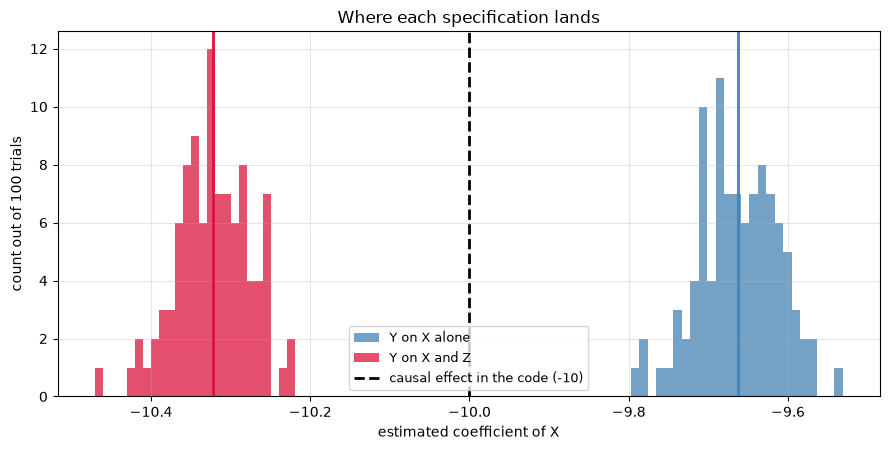

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(coef_x_only, bins=25, alpha=0.75, color="steelblue", label="Y on X alone")
ax.hist(coef_x_with_z, bins=25, alpha=0.75, color="crimson", label="Y on X and Z")
ax.axvline(-10, color="black", ls="--", lw=2, label="causal effect in the code (-10)")
ax.axvline(coef_x_only.mean(), color="steelblue", lw=2)
ax.axvline(coef_x_with_z.mean(), color="crimson", lw=2)
ax.set_xlabel("estimated coefficient of X")
ax.set_ylabel(f"count out of {TRIALS} trials")
ax.set_title("Where each specification lands")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 

In [7]:
check_rng = np.random.default_rng(SEED + 99)
raw_coefs, floored_coefs = [], []
for _ in range(20):
    difficulty = check_rng.uniform(0, 1, (NUM,))
    unfloored = check_rng.normal(15, 5, (NUM,)) - difficulty * 10
    floored = np.maximum(unfloored, 0)
    raw_coefs.append(ols(unfloored, difficulty)[1])
    floored_coefs.append(ols(floored, difficulty)[1])

print(f"slope with no floor applied : {np.mean(raw_coefs):.6f}   (the -10 written in the code)")
print(f"slope after the floor at 0  : {np.mean(floored_coefs):.6f}")
print(f"attenuation from the floor  : {np.mean(floored_coefs) - np.mean(raw_coefs):+.6f}")

slope with no floor applied : -9.991024   (the -10 written in the code)
slope after the floor at 0  : -9.653472
attenuation from the floor  : +0.337552


## 6. 

In [8]:
d = make_data(NUM, np.random.default_rng(SEED + 7))
d["z_band"] = pd.qcut(d["accident"], q=5)

rows = []
for band, g in d.groupby("z_band", observed=True):
    rows.append({"accident band": str(band), "n": len(g),
                 "slope of Y on X inside the band": ols(g["speed"], g["difficulty"])[1]})
within = pd.DataFrame(rows)

print(f"slope ignoring Z entirely: {ols(d['speed'], d['difficulty'])[1]:.6f}\n")
print("inside narrow bands of Z the slope is pulled away from the truth:")
within

slope ignoring Z entirely: -9.634459

inside narrow bands of Z the slope is pulled away from the truth:


,accident band,n,slope of Y on X inside the band
0,"(-0.001, 0.222]",20000,-9.314733
1,"(0.222, 0.42]",20000,-10.227714
2,"(0.42, 0.588]",20000,-10.430032
3,"(0.588, 0.786]",20000,-10.677268
4,"(0.786, 1.0]",20000,-10.496310


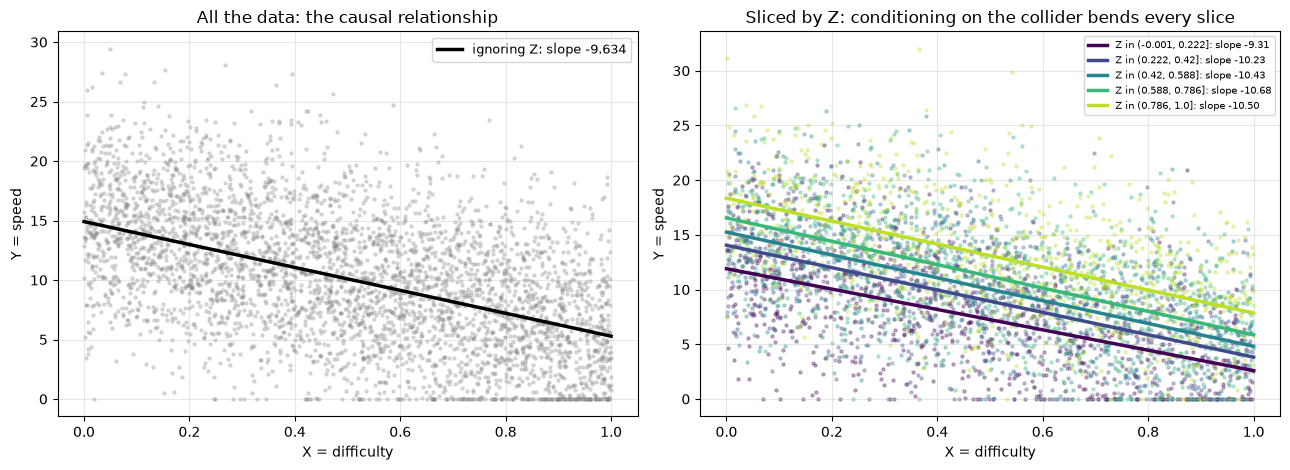

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sample = d.sample(4000, random_state=0)

axes[0].scatter(sample["difficulty"], sample["speed"], s=5, alpha=0.25, color="grey")
grid = np.linspace(0, 1, 50)
bb = ols(d["speed"], d["difficulty"])
axes[0].plot(grid, bb[0] + bb[1] * grid, color="black", lw=2.5,
             label=f"ignoring Z: slope {bb[1]:.3f}")
axes[0].set_xlabel("X = difficulty"); axes[0].set_ylabel("Y = speed")
axes[0].set_title("All the data: the causal relationship")
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

colors = plt.cm.viridis(np.linspace(0, 0.9, d["z_band"].nunique()))
for (band, g), col in zip(d.groupby("z_band", observed=True), colors):
    gs = g.sample(min(800, len(g)), random_state=0)
    axes[1].scatter(gs["difficulty"], gs["speed"], s=5, alpha=0.3, color=col)
    bg = ols(g["speed"], g["difficulty"])
    axes[1].plot(grid, bg[0] + bg[1] * grid, color=col, lw=2.5,
                 label=f"Z in {band}: slope {bg[1]:.2f}")
axes[1].set_xlabel("X = difficulty"); axes[1].set_ylabel("Y = speed")
axes[1].set_title("Sliced by Z: conditioning on the collider bends every slice")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Answers

In [15]:
print(f"Monte Carlo over {TRIALS} data sets of {NUM:,} rows\n")
print(f"  Q1  Y regressed on X alone")
print(f"        average coefficient of X = {coef_x_only.mean():.4f}")
print(f"        (the causal effect written into the code is -10, slightly attenuated")
print(f"         by the floor at zero speed)\n")
print(f"  Q2  Y regressed on X and Z")
print(f"        average coefficient of X = {coef_x_with_z.mean():.4f}")
print(f"        shifted by {coef_x_with_z.mean() - coef_x_only.mean():+.4f} "
      f"relative to the correct specification\n")

Monte Carlo over 100 data sets of 100,000 rows

  Q1  Y regressed on X alone
        average coefficient of X = -9.6627
        (the causal effect written into the code is -10, slightly attenuated
         by the floor at zero speed)

  Q2  Y regressed on X and Z
        average coefficient of X = -10.3224
        shifted by -0.6597 relative to the correct specification

